In [1]:
import matplotlib.pyplot as plt
import numpy as np
from proxlib.prox import proxL1
from proxlib.utils import plot_convergence
from proxlib.algorithms import ISTA, FISTA, metrics

# support functions
def sample_generation(m=100, n = 500, s = 10, sigma = 0.01, seed = 0):
    rng = np.random.default_rng(seed)  
    A = rng.standard_normal((m,n))/np.sqrt(m)
    x_true = np.zeros(n)
    idxs = rng.choice(n, size = s, replace=False)
    for i in idxs:
        x_true[i] = rng.choice([-1.0,1.0]) * (1 + np.abs(rng.standard_normal()))
    eps = rng.normal(0.0,sigma,m)
    b = A @ x_true + eps
    return {"A": A, "b": b, "x_true": x_true, "eps": eps, 'idxs': idxs}

# gradient of f = 1/2 * norm_2{Ax-b}^2
def grad_f(x,A,b):
    return A.T @ (A @ x - b)

def F(x,A,b,lambd):
    return 0.5 * np.linalg.norm((A @ x - b),2)**2 + lambd * np.linalg.norm(x,1)

def lipschitz_const(A):
    return np.linalg.norm(A,2)**2

In [2]:
gen = sample_generation()

A = gen["A"]
b = gen["b"]
x_true = gen['x_true']
eps = gen['eps']
idxs = gen['idxs']
L = lipschitz_const(A)
lambd_max = np.linalg.norm(A.T@b, np.inf)
lambd = 0.01 * np.sqrt(2 * np.log(A.shape[1]))

In [3]:
# select F*
tol = 1e-8
x_star, F_hist_ref = FISTA(A, b, lambd, L, F=F, grad_f=grad_f, prox=proxL1,max_iter=20000)
F_star = F_hist_ref.min() 

### Bounds of methods

For ISTA we have:
$$
F(x_k) - F^* \leq \frac{L ||x_0 - x^*||^2}{2k}
$$

For FISTA:

$$
F(x_k) - F^* \leq \frac{2L ||x_0 - x^*||^2}{(k+1)^2}
$$

ISTA : F(last) - F* = 1.13e-09
FISTA: F(last) - F* = 2.22e-16


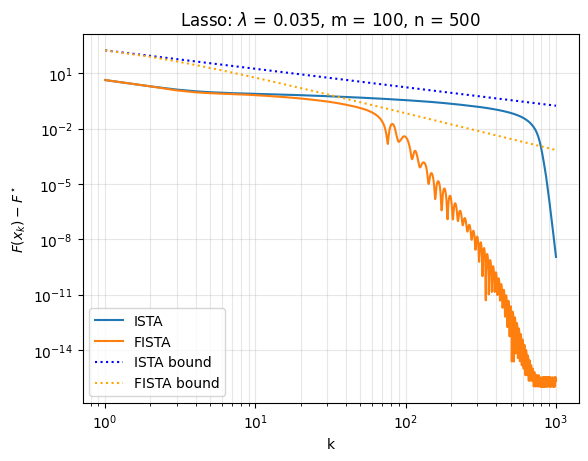

In [6]:
n_iter = 1000

x_ista,  F_ista  = ISTA (A, b, lambd, L, F=F, grad_f=grad_f, prox=proxL1, max_iter=n_iter)
x_fista, F_fista = FISTA(A, b, lambd, L, F=F, grad_f=grad_f, prox=proxL1, max_iter=n_iter)

print(f"ISTA : F(last) - F* = {F_ista[-1]  - F_star:.2e}")
print(f"FISTA: F(last) - F* = {F_fista[-1] - F_star:.2e}")

F_star = min(F_star, F_ista.min(), F_fista.min())

ax = plot_convergence({"ISTA": F_ista, "FISTA": F_fista}, F_star=F_star, title=rf"Lasso: $\lambda$ = {lambd:.3f}, m = {A.shape[0]}, n = {A.shape[1]}")

k = np.arange(1, len(F_ista))          
R2 = np.linalg.norm(x_star) ** 2     

ax.plot(k, L * R2 / (2 * k), color="blue", linestyle=":", label="ISTA bound")
ax.plot(k, 2 * L * R2 / (k + 1)**2, color="orange", linestyle=":", label="FISTA bound")
ax.legend()                           
plt.show()
